# 3. Graph convolution proper

**What you will learn:** what the GCN layer is, the job each piece of
$\hat{A} = \tilde{D}^{-1/2}(A+I)\tilde{D}^{-1/2}$ does, what breaks when you
remove a piece, and a numerical check that the layer here is the same as the
one in PyTorch Geometric.

Kipf, T. N.; Welling, M. "Semi-Supervised Classification with Graph
Convolutional Networks." ICLR 2017.
DOI: [10.48550/arXiv.1609.02907](https://doi.org/10.48550/arXiv.1609.02907)

The layer is one line:

$$ H^{(l+1)} = \sigma\!\left( \hat{A} \, H^{(l)} \, W^{(l)} \right) $$

Three factors. $W$ transforms features (an ordinary linear layer).
$\hat{A}$ moves them between atoms. $\sigma$ is a nonlinearity. All of the
graph-specific thinking is in $\hat{A}$, so that is where we spend the notebook.

caffeine: 14 heavy atoms, 15 bonds


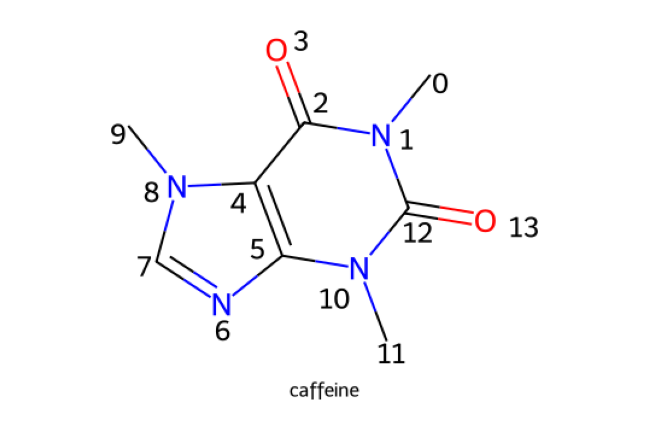

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from mgnn import features as F
from mgnn.layers import GCNLayer, gcn_normalised_adjacency, scatter_sum
from mgnn.viz import draw_molecule_with_indices, show

np.set_printoptions(precision=3, suppress=True, linewidth=130)
plt.rcParams["figure.dpi"] = 110
torch.manual_seed(0)

# Caffeine: a fused bicycle with degrees from 1 to 3, so normalisation has
# something to do.
smiles = "Cn1c(=O)c2c(ncn2C)n(C)c1=O"
graph = F.smiles_to_graph(smiles)
labels = [f"{s}{i}" for i, s in enumerate(graph.atom_symbols())]
print(f"caffeine: {graph.num_nodes} heavy atoms, {graph.num_edges // 2} bonds")
show(draw_molecule_with_indices(smiles, size=(520, 340), legend="caffeine"))
plt.show()

## 3.1 Four ways to aggregate

Take the same molecule and build four candidate propagation matrices:

| name | matrix | what it does |
|---|---|---|
| raw sum | $A$ | add up neighbours; forget yourself |
| sum with self-loops | $A + I$ | add up neighbours and yourself |
| row-normalised | $\tilde{D}^{-1}(A+I)$ | average over your neighbourhood |
| GCN symmetric | $\tilde{D}^{-1/2}(A+I)\tilde{D}^{-1/2}$ | average, discounted by *both* endpoints |

In [2]:
A = F.adjacency_matrix(graph)
n = graph.num_nodes
I = np.eye(n)
A_self = A + I
deg = A_self.sum(axis=1)

variants = {
    "raw sum  A": A,
    "self-loops  A+I": A_self,
    "row-normalised  D^-1 (A+I)": (1.0 / deg)[:, None] * A_self,
    "GCN  D^-1/2 (A+I) D^-1/2": (deg ** -0.5)[:, None] * A_self * (deg ** -0.5)[None, :],
}

summary = pd.DataFrame({
    name: {
        "row sum (min)": M.sum(axis=1).min(),
        "row sum (max)": M.sum(axis=1).max(),
        "symmetric": bool(np.allclose(M, M.T)),
        "keeps self": bool((np.diag(M) > 0).all()),
        "largest eigenvalue": float(np.abs(np.linalg.eigvals(M)).max()),
    } for name, M in variants.items()
}).T
display(summary.style.format({"row sum (min)": "{:.3f}", "row sum (max)": "{:.3f}",
                              "largest eigenvalue": "{:.3f}"}))

,row sum (min),row sum (max),symmetric,keeps self,largest eigenvalue
raw sum A,1.000,3.000,True,False,2.505
self-loops A+I,2.000,4.000,True,True,3.505
row-normalised D^-1 (A+I),1.000,1.000,False,True,1.000
GCN D^-1/2 (A+I) D^-1/2,0.854,1.142,True,True,1.000


The **largest eigenvalue** column is the one to read. It is the factor by which
a layer can amplify the overall scale of the features:

* raw sum and $A+I$ have eigenvalues above 1 — stack a few layers and
  activations blow up, which in practice shows up as a loss that goes to `nan`
  around layer four.
* both normalised forms are capped at 1 — stable to stack.

The symmetric form keeps the matrix **symmetric**, which the row-normalised
version does not. That matters for the theory (a symmetric operator has real
eigenvalues and behaves like a well-understood low-pass graph filter) and it
means a bond is discounted by how busy *both* of its atoms are, not just the
receiver. Kipf and Welling's choice, and the default everywhere since.

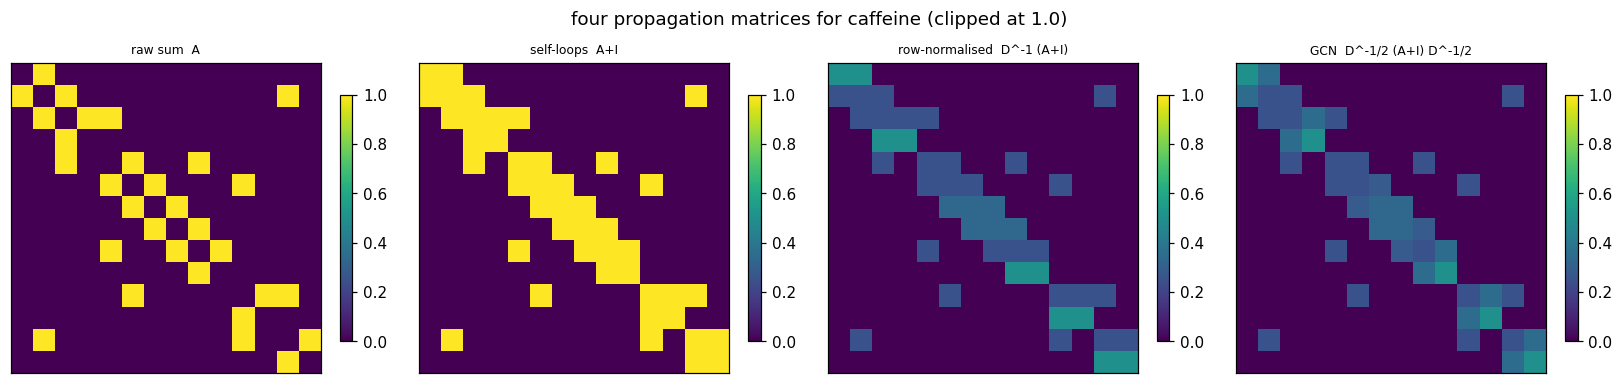

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (name, M) in zip(axes, variants.items()):
    im = ax.imshow(M, cmap="viridis", vmin=0, vmax=1.0)
    ax.set_title(name, fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, shrink=0.75)
fig.suptitle("four propagation matrices for caffeine (clipped at 1.0)")
fig.tight_layout()
plt.show()

## 3.2 What normalisation does to one atom

Caffeine has atoms of degree 1 (the methyls, the carbonyl oxygens) and degree 3
(the ring-fusion nitrogens). Feed in a constant signal of 1.0 on every atom and
look at what each atom receives under each scheme.

In [4]:
ones = np.ones((n, 1))
received = pd.DataFrame({name: (M @ ones).ravel() for name, M in variants.items()},
                        index=labels)
received.insert(0, "degree", A.sum(axis=1).astype(int))
display(received.style.format("{:.3f}").background_gradient(
    cmap="Reds", subset=list(variants.keys()), axis=None))

,degree,raw sum A,self-loops A+I,row-normalised D^-1 (A+I),GCN D^-1/2 (A+I) D^-1/2
C0,1.000,1.000,2.000,1.000,0.854
N1,3.000,3.000,4.000,1.000,1.104
C2,3.000,3.000,4.000,1.000,1.104
O3,1.000,1.000,2.000,1.000,0.854
C4,3.000,3.000,4.000,1.000,1.000
C5,3.000,3.000,4.000,1.000,1.039
N6,2.000,2.000,3.000,1.000,0.955
C7,2.000,2.000,3.000,1.000,0.955
N8,3.000,3.000,4.000,1.000,1.142
C9,1.000,1.000,2.000,1.000,0.854


With the raw sum, a degree-3 nitrogen receives three times what a methyl
carbon does, purely because of connectivity. Downstream, that difference is
indistinguishable from a chemical one. Both normalised schemes squash the
spread; the GCN form leaves a *little* degree information in (values are not
all identical), which is often argued to be a feature — an atom's degree is
chemically meaningful, it just should not dominate.

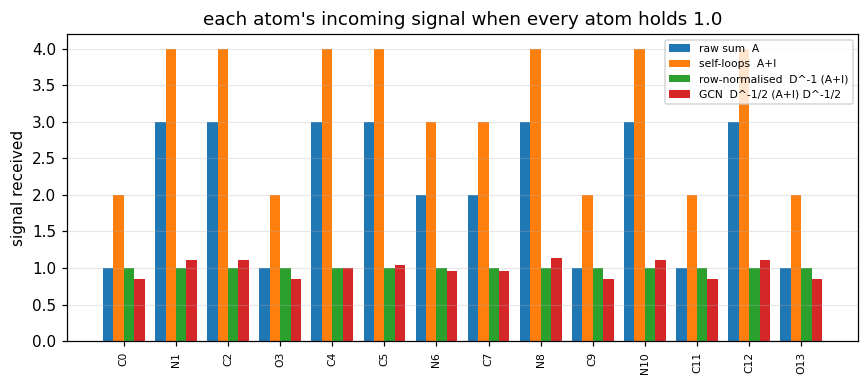

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
width = 0.2
for k, name in enumerate(variants):
    ax.bar(np.arange(n) + k * width, received[name], width, label=name)
ax.set_xticks(np.arange(n) + 1.5 * width, labels, rotation=90, fontsize=7)
ax.set_ylabel("signal received")
ax.set_title("each atom's incoming signal when every atom holds 1.0")
ax.legend(fontsize=7)
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.show()

## 3.3 What happens if you drop the self-loops

Without $+I$, an atom's new features are built purely from its neighbours. On
a **bipartite-ish** structure the effect is stark: information oscillates
between the two sides instead of settling. Here is the pulse experiment from
notebook 02 run with and without self-loops on benzene, which is perfectly
alternating.

In [6]:
benzene = F.smiles_to_graph("c1ccccc1")
A_b = F.adjacency_matrix(benzene)
deg_b = A_b.sum(axis=1)
no_loop = (deg_b ** -0.5)[:, None] * A_b * (deg_b ** -0.5)[None, :]
with_loop = gcn_normalised_adjacency(benzene.edge_index, 6).numpy()

pulse = np.zeros((6, 1)); pulse[0, 0] = 1.0
rows = []
h_no, h_yes = pulse.copy(), pulse.copy()
for k in range(7):
    rows.append({"layer": k,
                 "no self-loop: atom0": float(h_no[0]), "no self-loop: atom1": float(h_no[1]),
                 "with self-loop: atom0": float(h_yes[0]), "with self-loop: atom1": float(h_yes[1])})
    h_no, h_yes = no_loop @ h_no, with_loop @ h_yes
display(pd.DataFrame(rows).set_index("layer").style.format("{:.3f}"))

/tmp/ipykernel_407075/4264265844.py:12: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  "no self-loop: atom0": float(h_no[0]), "no self-loop: atom1": float(h_no[1]),
/tmp/ipykernel_407075/4264265844.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  "with self-loop: atom0": float(h_yes[0]), "with self-loop: atom1": float(h_yes[1])})


,no self-loop: atom0,no self-loop: atom1,with self-loop: atom0,with self-loop: atom1
layer,,,,
0,1.000,0.000,1.000,0.000
1,0.000,0.500,0.333,0.333
2,0.500,0.000,0.333,0.222
3,0.000,0.375,0.259,0.222
4,0.375,0.000,0.235,0.198
5,0.000,0.344,0.210,0.189
6,0.344,0.000,0.196,0.181


Without self-loops the signal flips between the odd and even positions of the
ring — atom 0 is empty at every odd layer. With self-loops it diffuses
smoothly. In a real model the oscillating version still trains, but it wastes
capacity on a parity artefact that has nothing to do with chemistry.

## 3.4 The layer, as code

`mgnn.layers.GCNLayer` is eight lines of arithmetic: build $\hat{A}$, apply
$W$, multiply, add bias.

In [7]:
layer = GCNLayer(F.ATOM_FEATURE_DIM, 16)
out = layer(graph.x, graph.edge_index)
print("in :", tuple(graph.x.shape), "-> out:", tuple(out.shape))
print("parameters:", sum(p.numel() for p in layer.parameters()))
print("\nnote the parameter count does not depend on the molecule size at all --")
print("the same W is reused for every atom of every molecule. That is the whole")
print("reason a GNN can train on thousands of molecules of different sizes.")

in : (14, 41) -> out: (14, 16)
parameters: 672

note the parameter count does not depend on the molecule size at all --
the same W is reused for every atom of every molecule. That is the whole
reason a GNN can train on thousands of molecules of different sizes.


## 3.5 Dense or sparse: same answer, different cost

`GCNLayer` builds the dense $N \times N$ matrix because that is how the
equation reads. Production code gathers and scatters along `edge_index`
instead, which is $O(E)$ rather than $O(N^2)$ — the difference between
feasible and hopeless on a 50,000-atom protein graph, and a measurable
difference even on a batch of a few hundred molecules.

Both are implemented below; they agree to float precision.

In [8]:
def gcn_sparse(x, edge_index, lin, bias):
    """Same layer, gather/scatter style."""
    n = x.shape[0]
    src, dst = edge_index[0], edge_index[1]
    loop = torch.arange(n)
    src = torch.cat([src, loop]); dst = torch.cat([dst, loop])    # self-loops
    deg = scatter_sum(torch.ones(dst.shape[0], 1), dst, n).squeeze(1)
    dinv = deg.pow(-0.5)
    h = lin(x)
    norm = (dinv[src] * dinv[dst]).unsqueeze(-1)
    return scatter_sum(h[src] * norm, dst, n) + bias

dense_out = layer(graph.x, graph.edge_index)
sparse_out = gcn_sparse(graph.x, graph.edge_index, layer.lin, layer.bias)
print("dense vs sparse max difference:",
      float((dense_out - sparse_out).abs().max()))

dense vs sparse max difference: 1.1920928955078125e-07


## 3.6 Checked against PyTorch Geometric

The claim this repository makes is that the from-scratch layers are the real
thing, not a simplification. Here is the check for GCN: copy the parameters
out of `GCNConv` into `GCNLayer` and compare outputs on real molecules.
`tests/test_layers_match_pyg.py` runs this for every layer on every test
molecule in CI.

In [9]:
from torch_geometric.nn import GCNConv   # noqa: E402

for smi in ["CCO", "c1ccccc1", "CC(=O)Nc1ccc(O)cc1", "C[N+](C)(C)C", "[Na+]"]:
    g = F.smiles_to_graph(smi)
    pyg = GCNConv(F.ATOM_FEATURE_DIM, 12)
    mine = GCNLayer(F.ATOM_FEATURE_DIM, 12).copy_weights_from_pyg(pyg)
    diff = float((pyg(g.x, g.edge_index) - mine(g.x, g.edge_index)).abs().max())
    print(f"  {smi:<22s} max |difference| = {diff:.2e}")

  CCO                    max |difference| = 1.19e-07
  c1ccccc1               max |difference| = 2.98e-08
  CC(=O)Nc1ccc(O)cc1     max |difference| = 1.19e-07
  C[N+](C)(C)C           max |difference| = 5.96e-08
  [Na+]                  max |difference| = 0.00e+00


## 3.7 Stacking, and the first sign of trouble

Three GCN layers with a nonlinearity between them. Watch the **variance across
atoms** of the hidden representations: if every atom ends up with the same
vector, that variance goes to zero and the model can no longer tell atoms
apart. Even at three layers it is already shrinking.

  after 0 conv layers: mean per-feature spread across atoms = 0.1432
  after 1 conv layers: mean per-feature spread across atoms = 0.0267
  after 2 conv layers: mean per-feature spread across atoms = 0.0112
  after 3 conv layers: mean per-feature spread across atoms = 0.0070
  after 4 conv layers: mean per-feature spread across atoms = 0.0035
  after 5 conv layers: mean per-feature spread across atoms = 0.0017
  after 6 conv layers: mean per-feature spread across atoms = 0.0012


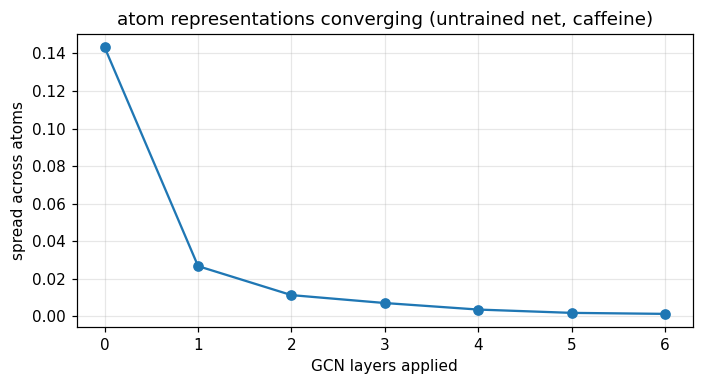

In [10]:
class TinyGCN(nn.Module):
    def __init__(self, hidden=32, n_layers=3):
        super().__init__()
        self.embed = nn.Linear(F.ATOM_FEATURE_DIM, hidden)
        self.convs = nn.ModuleList([GCNLayer(hidden, hidden) for _ in range(n_layers)])

    def forward(self, x, edge_index):
        h = self.embed(x)
        states = [h]
        for conv in self.convs:
            h = torch.relu(conv(h, edge_index))
            states.append(h)
        return states

torch.manual_seed(0)
states = TinyGCN(n_layers=6)(graph.x, graph.edge_index)
spread = [float(s.std(dim=0).mean()) for s in states]
for k, v in enumerate(spread):
    print(f"  after {k} conv layers: mean per-feature spread across atoms = {v:.4f}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(range(len(spread)), spread, marker="o")
ax.set_xlabel("GCN layers applied")
ax.set_ylabel("spread across atoms")
ax.set_title("atom representations converging (untrained net, caffeine)")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## What to take away

* $W$ transforms, $\hat{A}$ propagates. Only $\hat{A}$ is graph-specific.
* $+I$ keeps an atom's own features; without it, parity artefacts appear.
* $\tilde{D}^{-1/2} \cdot \tilde{D}^{-1/2}$ caps the spectral radius at 1 so
  layers can be stacked, and discounts a bond by the degree of both its atoms.
* Dense and sparse formulations are identical; use sparse for anything real.
* Repeated smoothing makes atoms converge. Notebook 06 quantifies it.

**Next:** notebook 04, the layer zoo — what GraphSAGE, GAT, GIN and D-MPNN
each change about the message, and what that buys.